Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel, SquareCoarseExtendedModel
from Components.Controllers import LTI_LQRc_RHG, LTI_LQRc_RHG_mixed_state
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [3]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [4]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")

In [5]:
n_well = model.well_to_agent.shape[0]

In [6]:
# Define base pumping commands
T = 100
base_command = np.split(np.kron(np.eye(n_well), -np.ones((1,T))), T*np.linspace(1,n_well-1,n_well-1, dtype=int), axis=1)
# Other pumping parameters
max_intensity = 1000
n_steps_intensity = 10
intensity_step = max_intensity/n_steps_intensity

In [7]:
# Compute heads and costs for different commands at different wells
head = np.array([[np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_steps_intensity] * n_well)
cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        system.state = system.initial_state.copy()
        intensity = (step+1)*intensity_step
        for k in range(T):
            system.apply_command(intensity*base_command[ii][:, [k]])
            head[ii, step, :, k+1] = model.translate_state(system.get_state()[0,:,:]).flatten()
            cost[ii, step, :, k] = system.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 10/10 [01:17<00:00,  7.77s/it]


In [8]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head = np.array([[np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_steps_intensity] * n_well)
model_cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        intensity = (step+1)*intensity_step
        for k in range(T):
            input = model.input_to_well.T @ (intensity*base_command[ii][:, [k]])
            model.state = model_head[ii, step, :, [k]].T
            model_head[ii, step, :, k+1] = (model.A @ model_head[ii, step, :, [k]].T + B @ input + model.C).flatten()
            model_cost[ii, step, :, k] = model.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 10/10 [00:00<00:00, 16.35it/s]


#### Plot head gaps for the different setups

In [9]:
well_pos = np.nonzero(model.well_to_cell.T)[1]

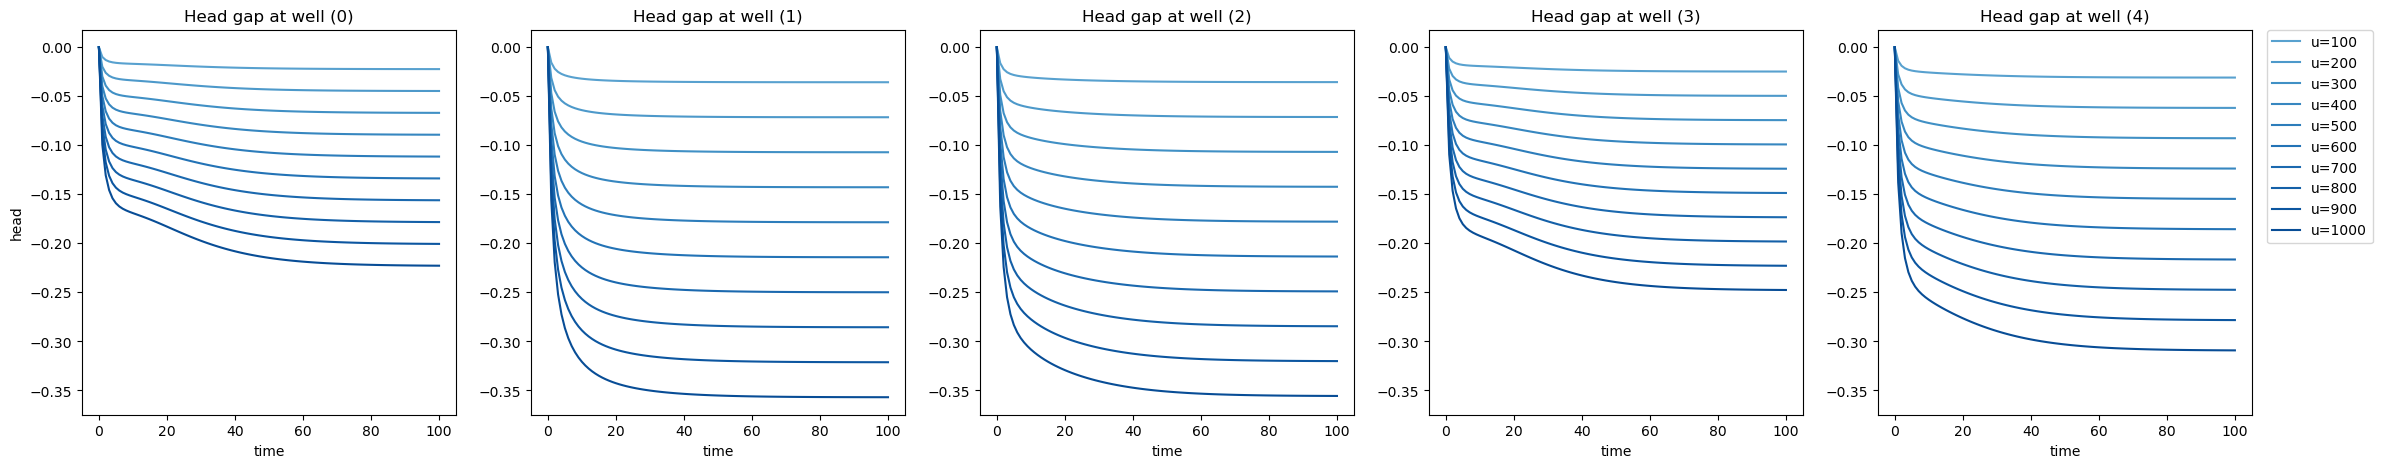

In [10]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for n_i in range(n_steps_intensity):
        # ax_h.plot(response[ii][n_i][well_pos[ii], :], "b-")
        # ax_h.plot(model_response[ii][n_i][well_pos[ii], :], "b--")
        ax_h.plot(model_head[ii, n_i, well_pos[ii], :] - head[ii, n_i, well_pos[ii], :], color=plt.get_cmap('Blues')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#### Plot cost gap

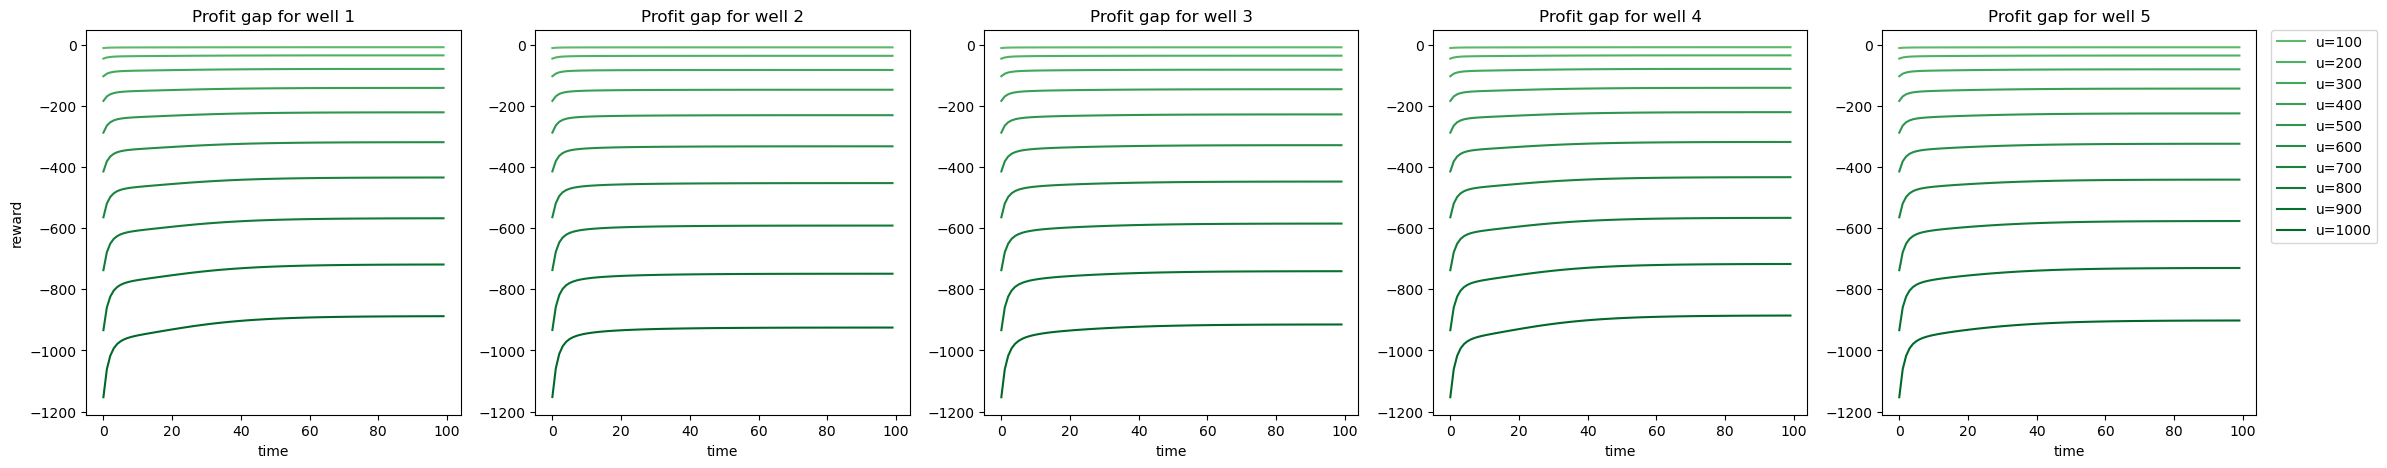

In [11]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    for n_i in range(n_steps_intensity):
        ax_p.plot(model_cost[ii, n_i, model.well_to_agent[ii], :] - cost[ii, n_i, model.well_to_agent[ii], :], color=plt.get_cmap('Greens')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Search for patterns

The head gap looks more or less linear in the pumping rate, and the cost gap quadratic

In [1]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity), model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green")

NameError: name 'plt' is not defined

Fit quadratic function

In [ ]:
from scipy.optimize import least_squares
params = []
intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
for ii in range(n_well):
    gap = model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1]
    res = least_squares(lambda x : (intensities*(x*intensities)) - gap, x0 = 0)
    params.append(res.x)

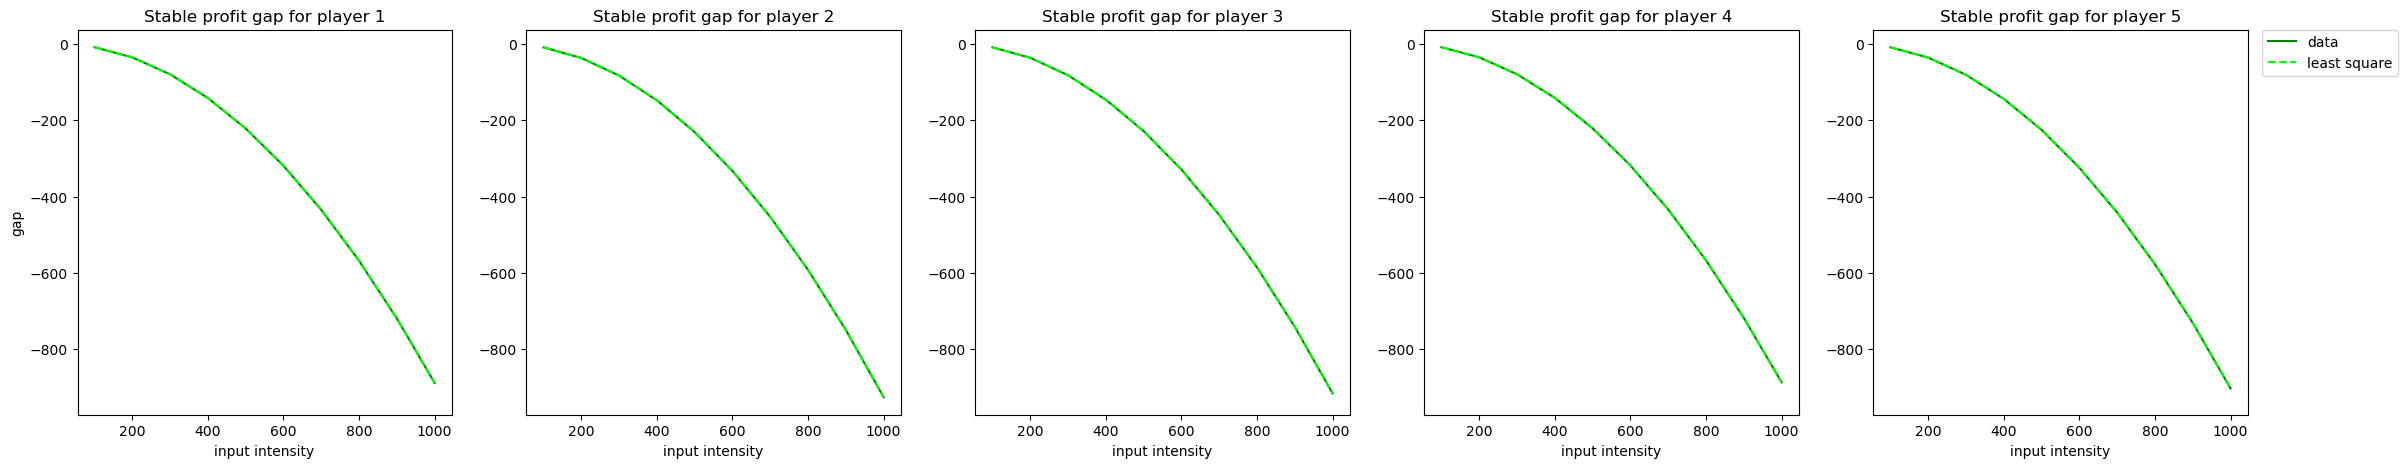

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
    ax_p.plot(intensities, model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green", label="data")
    ax_p.plot(intensities, intensities*(params[ii]*intensities), color="lime", linestyle="--", label="least square")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [ ]:
params

[array([-0.00088779]),
 array([-0.00092503]),
 array([-0.00091488]),
 array([-0.00088567]),
 array([-0.00090186])]

In [ ]:
intensities = np.tile(intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity), n_well)
gap = np.hstack([model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1] for ii in range(n_well)])
res = least_squares(lambda x : (intensities*(x*intensities) - gap), x0 = 0)
c_u = res.x

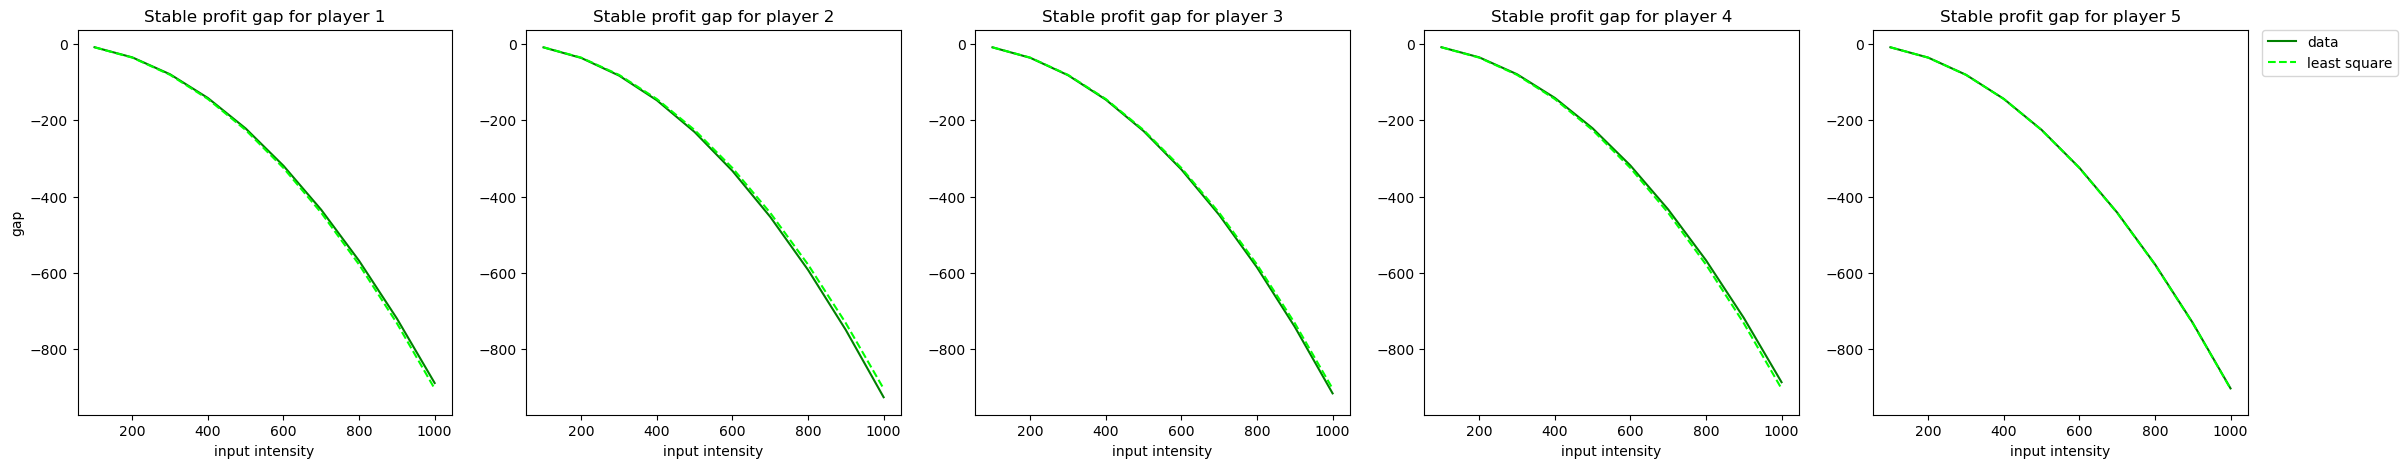

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
    ax_p.plot(intensities, model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green", label="data")
    ax_p.plot(intensities, intensities*(c_u*intensities), color="lime", linestyle="--", label="least square")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Test Gap w.r.t. cell size

In [18]:
setups = ["Components/Setup/cell_size_variation/4x4.json", "Components/Setup/cell_size_variation/5x5.json", "Components/Setup/cell_size_variation/10x10.json", "Components/Setup/cell_size_variation/20x20.json", "Components/Setup/cell_size_variation/25x25.json"]
n_sizes = len(setups)
u_bar = 1000

In [19]:
models = []
for parameter_file in setups:
    models.append(SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head"))

In [20]:
# Compute expected heads for those setup
system.state = system.initial_state.copy()
model_head_cs = []
model_cost_cs = []
for ii in range(n_well):
    model_head_cs.append([])
    model_cost_cs.append([])
    for s in trange(n_sizes):
        model_head_cs[ii].append(np.hstack((models[s].translate_state(system.get_state()[0,:,:]), np.zeros((models[s].nx, T)))))
        model_cost_cs[ii].append(np.zeros((models[s].n_agent, T)))
        intensity = u_bar
        B = sp.hstack(models[s].B_v)
        for k in range(T):
            models[s].state = model_head_cs[ii][s][:, [k]]
            input = models[s].input_to_well.T @ (intensity*base_command[ii][:, [k]])
            model_head_cs[ii][s][:, k+1] = (models[s].A @ model_head_cs[ii][s][:, [k]] + B @ input + models[s].C).flatten()
            model_cost_cs[ii][s][:, k] = models[s].compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 5/5 [00:00<00:00, 14.42it/s]


In [21]:
# Compute real heads and costs
head_hr = np.array([np.hstack((system.get_state()[0,:,:].reshape(-1,1), np.zeros((system.get_state()[0,:,:].shape[0]*system.get_state()[0,:,:].shape[1], T))))] * n_well)
cost_hr = np.array([np.zeros((model.n_agent, T))] * n_well)
for ii in range(n_well):
    system.state = system.initial_state.copy()
    intensity = u_bar
    for k in trange(T):
        system.apply_command(intensity*base_command[ii][:, [k]])
        head_hr[ii, :, k+1] = system.get_state()[0,:,:].flatten()
        cost_hr[ii, :, k] = system.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 100/100 [00:07<00:00, 12.85it/s]


#### Plot head gaps for the different setups

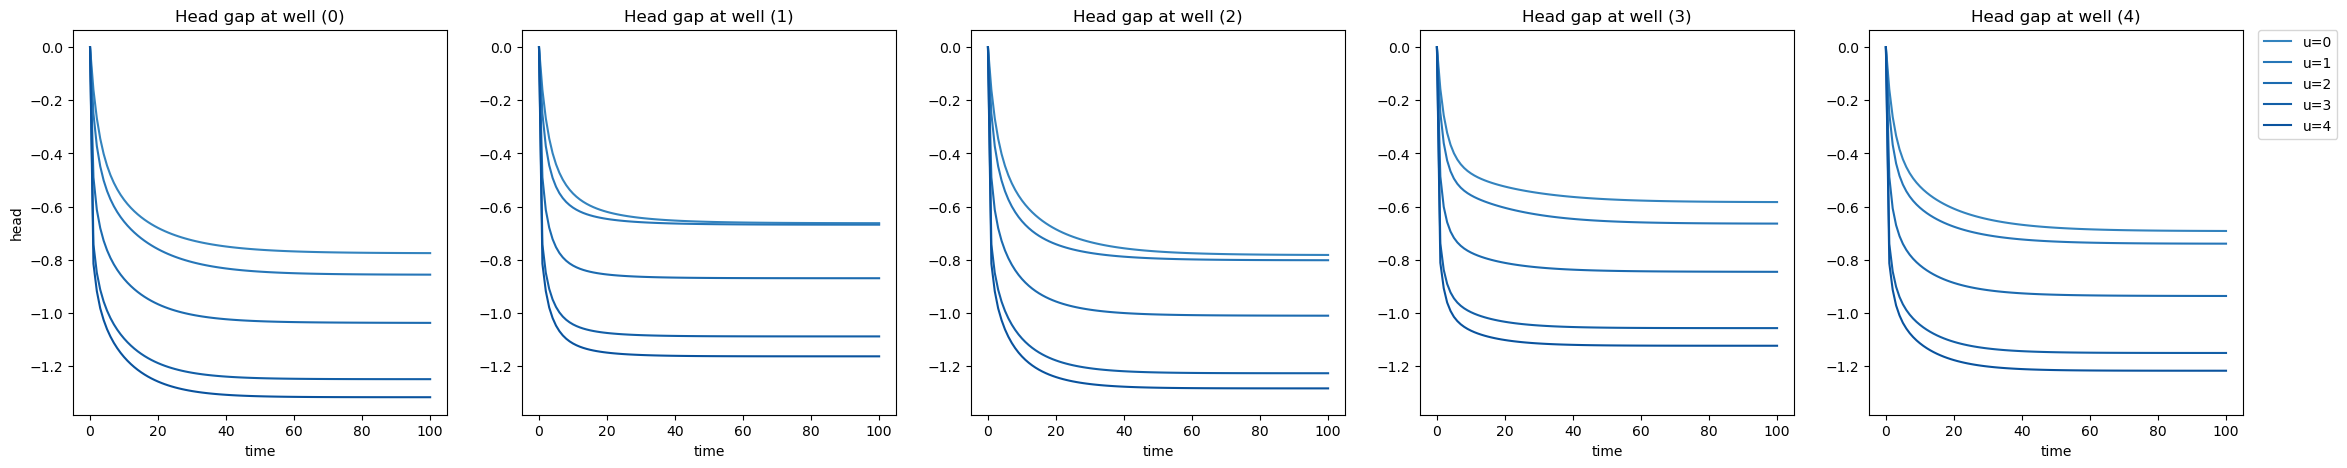

In [22]:
well_pos_hr = [49*49, 80*70, 35*60, 50*45, 45*62]
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for s in range(n_sizes):
        well_pos = np.nonzero(models[s].well_to_cell.T)[1]
        ax_h.plot(model_head_cs[ii][s][well_pos[ii], :] - head_hr[ii, well_pos_hr[ii], :], color=plt.get_cmap('Blues')((15+s)/(n_sizes+17)), label=f"u={int(s)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#### Plot cost gap

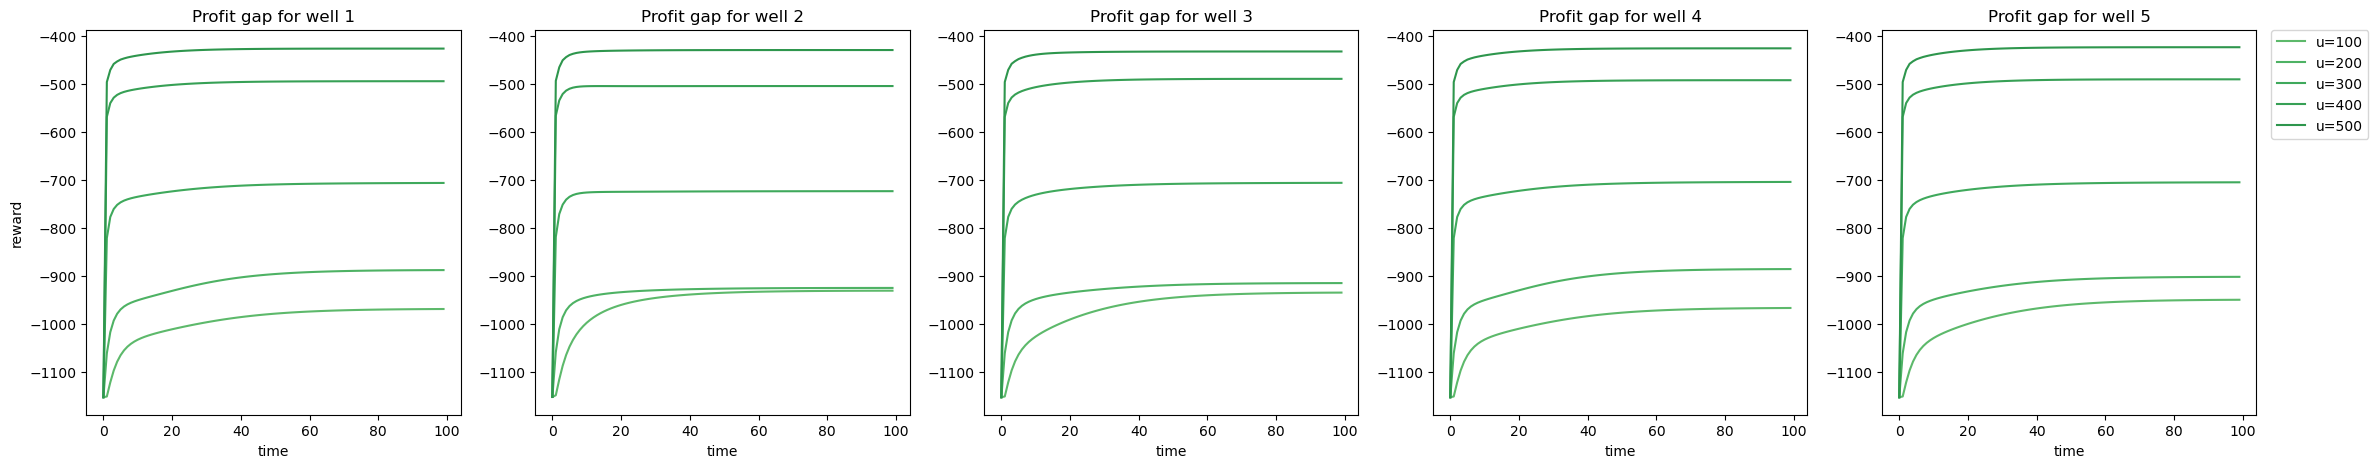

In [23]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    for s in range(n_sizes):
        ax_p.plot(model_cost_cs[ii][s][model.well_to_agent[ii], :] - cost_hr[ii, model.well_to_agent[ii], :], color=plt.get_cmap('Greens')((15+s)/(n_steps_intensity+17)), label=f"u={int((s+1)*intensity_step)}")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Search for patterns

The head gap looks more or less linear in the pumping rate, and the cost gap quadratic

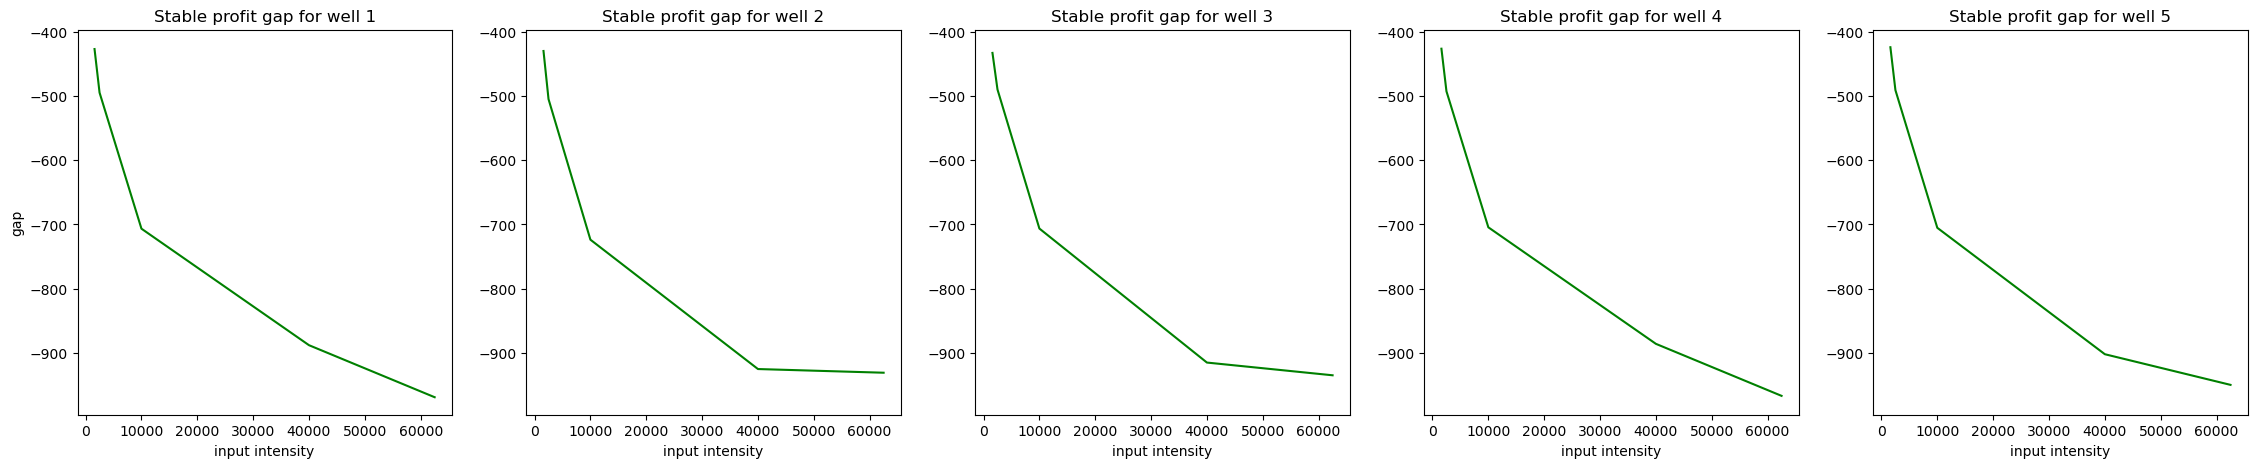

In [24]:
sizes = [(1000*1000)/(4*4), (1000*1000)/(5*5), (1000*1000)/(10*10), (1000*1000)/(20*20), (1000*1000)/(25*25)]
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(sizes, np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1], color="green")

In [ ]:
sizes_list = np.tile(sizes, n_well)
gap = np.hstack([np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1] for ii in range(n_well)])
res = least_squares(lambda x : -(x[0]*np.log(sizes_list) + x[1] - gap), x0 = [0,0])
c_A = res.x

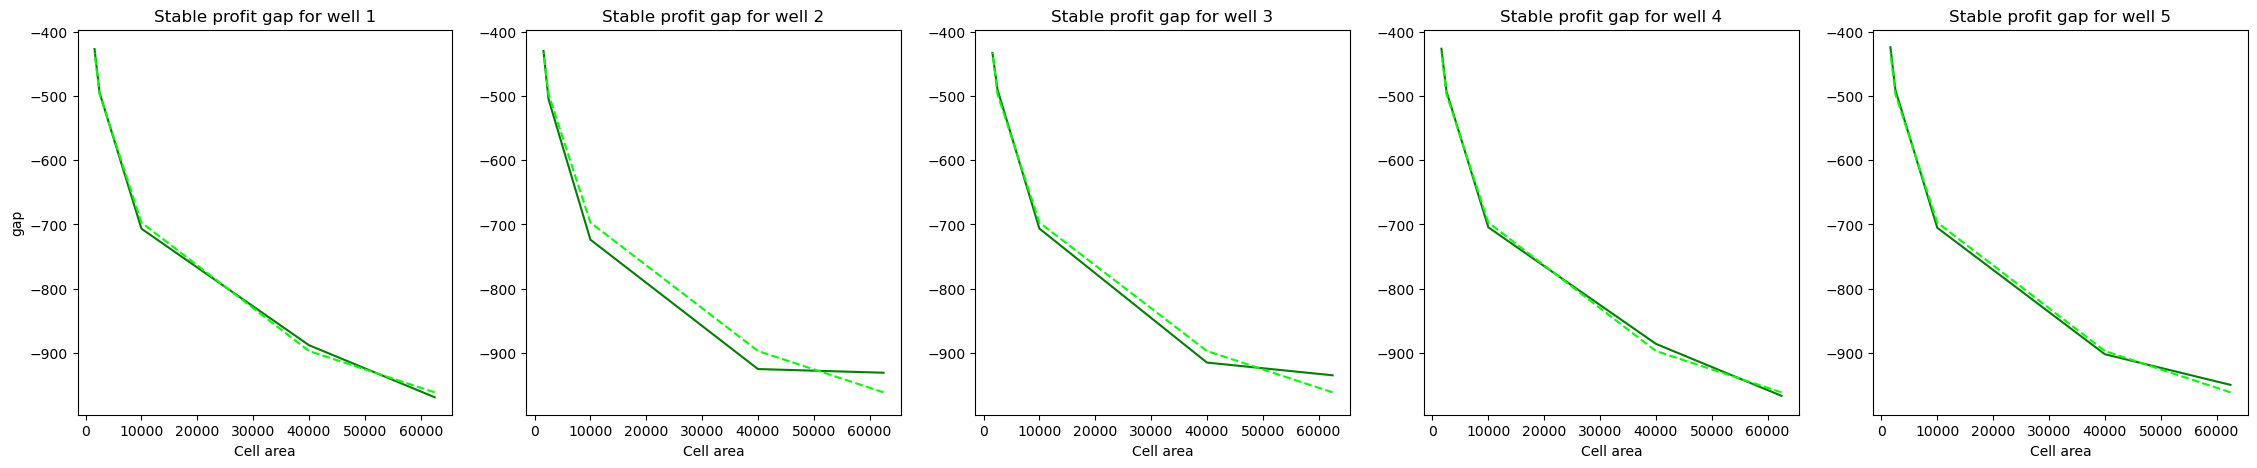

In [26]:
sizes = np.array([(1000*1000)/(4*4), (1000*1000)/(5*5), (1000*1000)/(10*10), (1000*1000)/(20*20), (1000*1000)/(25*25)])
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("Cell area")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(sizes, np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1], color="green")
    ax_p.plot(sizes, c_A[0]*np.log(sizes) + c_A[1], color="lime", linestyle="--", label="least square")

As expected given the Theis solution, the gap and the size of the cell are related by a logarithmic function.

# Cost augmentation

We can then augment the cost using these observation. We add the correction term $\delta(u,A)$, with:

$\begin{cases} \delta(u,\bar A) = c^u(\bar A) u^2 \qquad &\text{with } \bar A \in \mathbb R^+\\
\delta(\bar u,A)\ = c^A_1(\bar u) \log(A) + c^A_2(\bar u) \qquad &\text{with } \bar u \in \mathbb R^- \end{cases}$

So finally, if we compute $c^A_1(\bar u)$, $c^A_2(\bar u)$ for some $\bar u$, we have:

$\delta(u,A) = \left(c^A_1(\bar u) \log(A) + c^A_2(\bar u)\right)\left(\frac{u}{\bar u}\right)^2$

Let's verify this relation

In [27]:
(c_A[0]*np.log((1000/model.n_col)*(1000/model.n_row)) + c_A[1])/(u_bar**2), c_u

(np.float64(-0.0008972689241796068), array([-0.00090305]))

Ok! Very similar.

Now, let's augment the cost

In [28]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [29]:
n_well_per_input = [model.input_to_well[model.well_to_agent==v, :].sum(axis=0) for v in range(model.n_agent)]
n_well_per_input = [n_w_p_i[n_w_p_i>0] for n_w_p_i in n_well_per_input]

In [30]:
R_v = [(-c_u)*np.diag(n_w_p_i) for n_w_p_i in n_well_per_input]
R_v

[array([[0.00180609]]),
 array([[0.00090305, 0.        ],
        [0.        , 0.00090305]]),
 array([[0.00090305]])]

In [31]:
model_copy = copy.deepcopy(model)
def compute_augmented_cost(u: np.ndarray) -> np.ndarray:
    cost = np.zeros((model_copy.n_agent, 1))
    for v in range(model_copy.n_agent):
        input_indices = np.nonzero(model_copy.well_to_cell[:,model_copy.well_to_agent==v].T)[1]
        cost[v] = (-model_copy.extraction_cost[v] * (model_copy.initial_state[input_indices] -\
            model_copy.state[input_indices]) * u[model_copy.well_to_agent==v] + \
                model_copy.production_profit[v] * u[model_copy.well_to_agent==v] -\
                    c_u * u[model_copy.well_to_agent==v]**2).sum()
    return cost
model_copy.compute_cost = compute_augmented_cost

In [32]:
system_bis = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")

In [33]:
# Initialize Controller
controller = LTI_LQRc_RHG_mixed_state(
    parameter_file,
    model_copy.A.toarray(), [B.toarray() for B in model_copy.B_v], model_copy.C,
    [A.toarray() for A in model_copy.A_s_v], [B.toarray() for B in model_copy.B_s_v], [C.toarray() for C in model_copy.C_s_v],
    model_copy.H_x, model_copy.h_x, model_copy.H_u_v, model_copy.h_u_v,
    None, None,
    Q_v = [G.toarray() for G in model_copy.Gamma_v_tilde], R_v = R_v, M_v = None, L_v = [Xi for Xi in model_copy.Xi_v],
    solver='fbrs'
)

In [34]:
np.linalg.eigvals((controller.F.T + controller.F).toarray())[np.linalg.eigvals((controller.F.T + controller.F).toarray())>0], \
np.linalg.eigvals((controller.F.T + controller.F).toarray())[np.linalg.eigvals((controller.F.T + controller.F).toarray())<0]

(array([10.09547086,  9.28315162,  8.93994169,  8.7315907 ,  8.58077366,  8.46404977,  7.1677193 ,  8.37222506,  8.29787688,  8.23742861,  8.18726758,  8.14559952,  8.1104311 ,  8.08075567,  8.05539708,  8.03375209,  8.01509562,  6.07797325,  7.99904838,  7.98514907,  7.97314995,  7.96275114,  6.03684875,  7.95378605,  7.94605749,  7.9338383 ,  7.93945139,  7.92913996,  7.92527328,  7.92218607,  7.91816849,  7.91982832,  7.91718156,  5.67425284,  5.51748841,  5.42086419,  5.29666873,  5.38396015,  5.21154445,  5.16662597,  5.15682044,  5.05023406,  5.02975064,  4.97086731,  4.94940322,  4.90157809,  4.86412853,  4.82548857,  4.80757048,  4.78487935,  4.73971072,  4.71606643,  4.71026352,  4.68549191,  4.63055387,  4.64603853,  4.63980207,  4.60076209,  4.59225869,  4.56717347,  4.56291229,  4.53814541,  4.54723218,  4.51295929,  4.50842042,  4.50925887,  4.49104014,  4.2429386 ,  4.24380059,  4.24525292,  4.2473203 ,  4.4770604 ,  4.2500372 ,  4.25345216,  4.4719141 ,  4.46415905,  4.2

In [35]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system_bis, model_copy, controller, parameter_file)

In [36]:
# Run loop
receding_horizon.run(time_period=200, display_results=True)

Simulation progress:  72%|███████▏  | 144/200 [00:35<00:13,  4.11it/s]
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/ast.py:608: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use valu

KeyboardInterrupt: 

In [37]:
model.well_to_agent

array([0, 2, 1, 0, 1])

In [38]:
data = np.load("run_data/run_20250523-112653/result_data.npz")

In [39]:
data['q_rates'][1,-1], data['avg_h_wells'][1,-1]

(np.float64(-656.680290227619), np.float64(9.724301743507379))

In [40]:
(10-data['avg_h_wells'][0,-1])*data['q_rates'][0,-1]*2 - 2*data['q_rates'][0,-1]*2 + c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2,\
(10-data['avg_h_wells'][1,-1])*data['q_rates'][1,-1] - 2*data['q_rates'][1,-1] + c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1]

(array([326.09426453]), array([742.89499371]))

In [41]:
compute_augmented_cost(data['q_rates'][:,[-1]])

array([[-368.55381471],
       [-995.03916574],
       [-742.89499371]])

In [42]:
data['real_profit'][:,-1]

array([361.56079946, 713.9590342 , 534.17523738])

For me, the gap that is still there comes from the effect of the interactions between the wells.

In [43]:
c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2, c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1]

(array([-84.91909452]), array([-389.41997566]))

In [44]:
(data['real_profit'][0,-1]-data['model_profit'][0,-1])/(c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2), \
    (data['real_profit'][2,-1]-data['model_profit'][2,-1])/(c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1])

(array([0.08234912]), array([0.53597599]))